In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", context="notebook")

data_path = Path("../results/sweep_bias_accuracy/sweep_results.json")  # <- archivo correcto
with open(data_path, "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)

df["acc_gap"] = (df["acc_male"] - df["acc_female"]).abs()
df["auc_gap"] = (df["auc_male"] - df["auc_female"]).abs()
df["tpr_gap_abs"] = df["tpr_gap"].abs()  # por robustez

df.head()

,alpha,ls,accuracy,tpr_male,tpr_female,tpr_gap,auc_all,auc_male,auc_female,acc_male,acc_female,acc_gap,auc_gap,tpr_gap_abs
0,0.0,32,0.849345,0.776860,0.777778,0.000918,0.841739,0.835584,0.847536,0.836066,0.864486,0.028420,0.011951,0.000918
1,0.0,64,0.834061,0.776860,0.802469,0.025610,0.829111,0.819324,0.841084,0.819672,0.850467,0.030795,0.021760,0.025610
2,0.0,128,0.792576,0.818182,0.888889,0.070707,0.798267,0.758684,0.842941,0.758197,0.831776,0.073579,0.084256,0.070707
3,0.0,256,0.834061,0.727273,0.765432,0.038159,0.824412,0.810791,0.841363,0.811475,0.859813,0.048338,0.030572,0.038159
4,0.0,512,0.803493,0.710744,0.728395,0.017651,0.794458,0.802526,0.789010,0.803279,0.803738,0.000460,0.013517,0.017651


In [2]:
# Cell 6: frontera de Pareto (max accuracy, min tpr_gap_abs)
def pareto_frontier(dfin, x_col="tpr_gap_abs", y_col="accuracy"):
    pts = dfin[[x_col, y_col, "alpha", "ls"]].sort_values([x_col, y_col], ascending=[True, False]).reset_index(drop=True)
    frontier = []
    best_y = -np.inf
    for _, r in pts.iterrows():
        if r[y_col] > best_y:
            frontier.append(r)
            best_y = r[y_col]
    return pd.DataFrame(frontier)

pareto = pareto_frontier(df)

print("Configuraciones en frontera de Pareto (equidad vs accuracy):")
display(pareto[["alpha", "ls", "tpr_gap_abs", "accuracy"]].sort_values("tpr_gap_abs"))

Configuraciones en frontera de Pareto (equidad vs accuracy):


,alpha,ls,tpr_gap_abs,accuracy
0,0.0,32.0,0.000918,0.849345


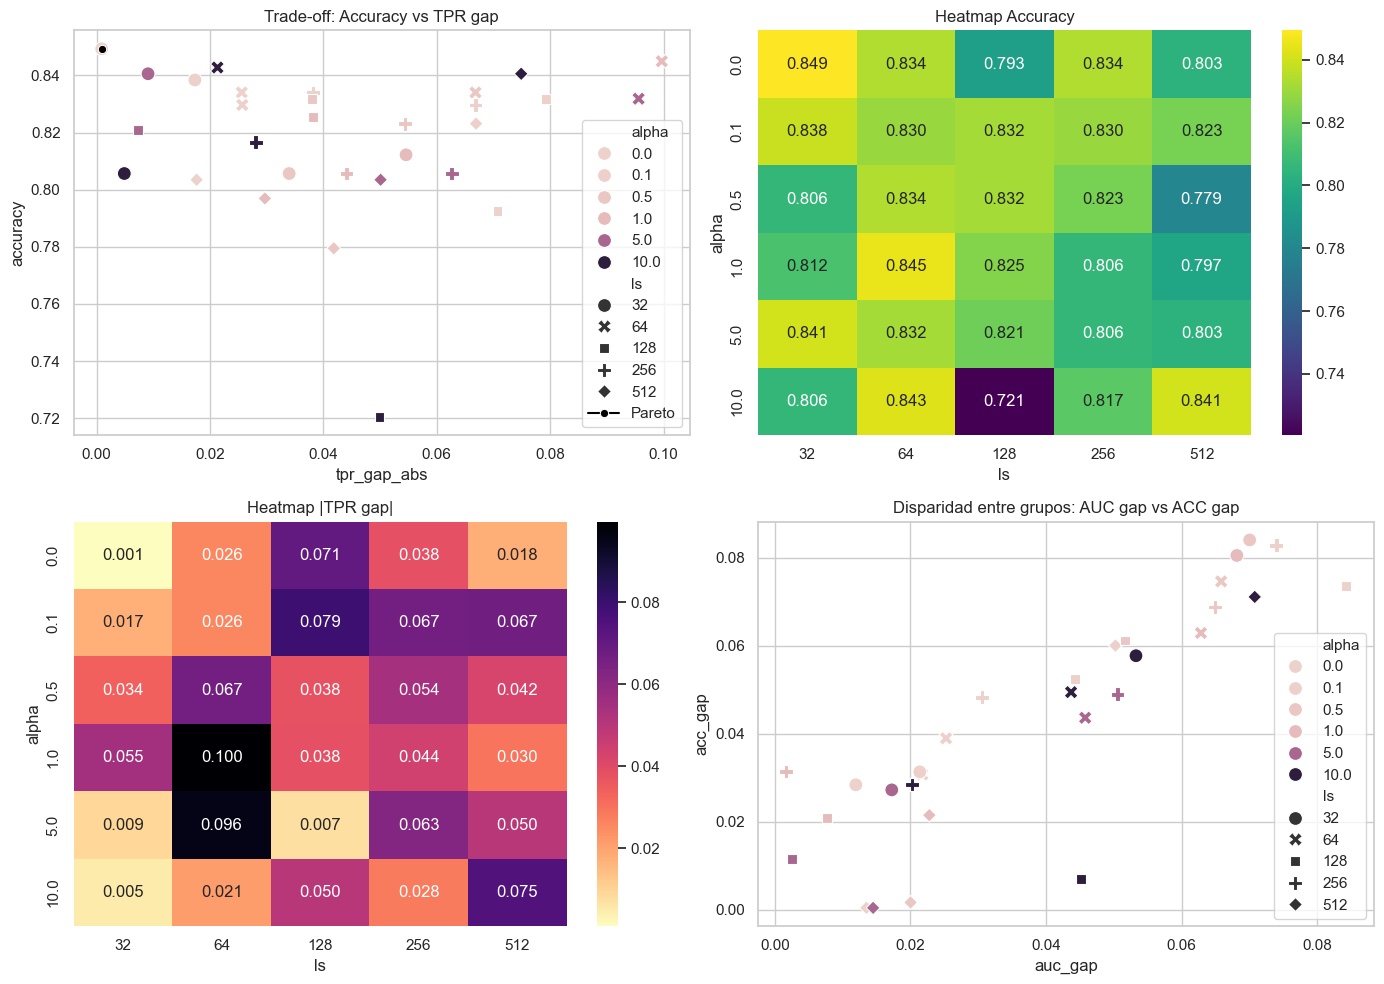

In [3]:
# Cell 7: visualizaciones
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) trade-off accuracy vs tpr_gap
sns.scatterplot(
    data=df, x="tpr_gap_abs", y="accuracy", hue="alpha", style="ls", s=100, ax=axes[0, 0]
)
sns.lineplot(
    data=pareto.sort_values("tpr_gap_abs"), x="tpr_gap_abs", y="accuracy",
    color="black", marker="o", ax=axes[0, 0], label="Pareto"
)
axes[0, 0].set_title("Trade-off: Accuracy vs TPR gap")

# (b) heatmap accuracy
pivot_acc = df.pivot(index="alpha", columns="ls", values="accuracy")
sns.heatmap(pivot_acc, annot=True, fmt=".3f", cmap="viridis", ax=axes[0, 1])
axes[0, 1].set_title("Heatmap Accuracy")

# (c) heatmap tpr_gap
pivot_gap = df.pivot(index="alpha", columns="ls", values="tpr_gap_abs")
sns.heatmap(pivot_gap, annot=True, fmt=".3f", cmap="magma_r", ax=axes[1, 0])
axes[1, 0].set_title("Heatmap |TPR gap|")

# (d) dispersión de disparidad por grupo
sns.scatterplot(data=df, x="auc_gap", y="acc_gap", hue="alpha", style="ls", s=100, ax=axes[1, 1])
axes[1, 1].set_title("Disparidad entre grupos: AUC gap vs ACC gap")

plt.tight_layout()
plt.show()

## Cell 8: análisis de `gender_prediction_auc` (archivo detallado)
En `sweep_bias_accuracy.json`, la métrica `gender_prediction_auc` aparece por capa y por iteración.

Interpretación rápida:
- AUC cercana a 1.0: el género se puede predecir muy bien desde esa representación (alta información de género).
- AUC cercana a 0.5: difícil predecir género (menor información de género).

Como capas 1–5 son casi constantes, nos enfocamos en la capa 6 para extraer conclusiones útiles.

In [4]:
# Carga y normalización de gender_prediction_auc desde el JSON detallado
import json
from pathlib import Path

raw_path = Path("../results/sweep_bias_accuracy/sweep_bias_accuracy.json")
with open(raw_path, "r", encoding="utf-8") as f:
    raw = json.load(f)

rows = []
for exp in raw:
    alpha = exp.get("alpha", exp.get("config", {}).get("alpha"))
    ls = exp.get("layer_size", exp.get("config", {}).get("layer_size"))
    for it in exp.get("iterations", []):
        metrics = it.get("metrics", {})
        gp = it.get("gender_prediction_auc", {})
        for layer_name, value in gp.items():
            rows.append(
                {
                    "experiment": exp.get("experiment"),
                    "alpha": alpha,
                    "ls": ls,
                    "iteration": it.get("iteration"),
                    "layer": int(layer_name.split("_")[-1]),
                    "gender_pred_auc": value,
                    "acc_all": metrics.get("all", {}).get("accuracy"),
                    "auc_all": metrics.get("all", {}).get("auc"),
                    "acc_male": metrics.get("male", {}).get("accuracy"),
                    "acc_female": metrics.get("female", {}).get("accuracy"),
                    "auc_male": metrics.get("male", {}).get("auc"),
                    "auc_female": metrics.get("female", {}).get("auc"),
                }
            )

gender_df = pd.DataFrame(rows)
print(f"Filas: {len(gender_df)} | experimentos: {gender_df['experiment'].nunique()} | capas: {sorted(gender_df['layer'].unique())}")

gender_df.head()

Filas: 900 | experimentos: 30 | capas: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


,experiment,alpha,ls,iteration,layer,gender_pred_auc,acc_all,auc_all,acc_male,acc_female,auc_male,auc_female
0,1,0.0,32,1,1,1.0,0.766,0.78,0.775,0.757,0.776,0.78
1,1,0.0,32,1,2,1.0,0.766,0.78,0.775,0.757,0.776,0.78
2,1,0.0,32,1,3,1.0,0.766,0.78,0.775,0.757,0.776,0.78
3,1,0.0,32,1,4,1.0,0.766,0.78,0.775,0.757,0.776,0.78
4,1,0.0,32,1,5,1.0,0.766,0.78,0.775,0.757,0.776,0.78


In [5]:
# Resumen por capa: ¿dónde cambia realmente la información de género?
layer_summary = (
    gender_df.groupby("layer")["gender_pred_auc"]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

print("Resumen gender_prediction_auc por capa")
display(layer_summary)

alpha_layer = (
    gender_df.groupby(["alpha", "layer"])["gender_pred_auc"]
    .mean()
    .unstack()
    .round(3)
)

print("Media por alpha y capa")
display(alpha_layer)

Resumen gender_prediction_auc por capa


,mean,std,min,max
layer,,,,
1,1.000,0.000,1.000,1.0
2,1.000,0.000,1.000,1.0
3,1.000,0.000,1.000,1.0
4,1.000,0.000,1.000,1.0
5,1.000,0.000,1.000,1.0
6,0.918,0.071,0.766,1.0


Media por alpha y capa


layer,1,2,3,4,5,6
alpha,,,,,,
0.0,1.0,1.0,1.0,1.0,1.0,0.922
0.1,1.0,1.0,1.0,1.0,1.0,0.926
0.5,1.0,1.0,1.0,1.0,1.0,0.917
1.0,1.0,1.0,1.0,1.0,1.0,0.925
5.0,1.0,1.0,1.0,1.0,1.0,0.912
10.0,1.0,1.0,1.0,1.0,1.0,0.906


In [6]:
# Análisis focalizado en layer 6 (única capa con variabilidad)
layer6 = (
    gender_df[gender_df["layer"] == 6]
    .copy()
)

layer6["acc_gap_abs"] = (layer6["acc_male"] - layer6["acc_female"]).abs()
layer6["auc_gap_abs"] = (layer6["auc_male"] - layer6["auc_female"]).abs()

print("Correlaciones de layer_6 gender_pred_auc con métricas")
for metric in ["acc_all", "auc_all", "acc_gap_abs", "auc_gap_abs"]:
    corr = layer6["gender_pred_auc"].corr(layer6[metric])
    print(f"  corr(gender_pred_auc, {metric}) = {corr:.3f}")

summary_alpha6 = (
    layer6.groupby("alpha")["gender_pred_auc"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(3)
)
print("\nDistribución en layer 6 por alpha")
display(summary_alpha6)

best_low_gender = (
    layer6.sort_values(["gender_pred_auc", "auc_all", "acc_all"], ascending=[True, False, False])
    .head(10)
)
print("Top-10 iteraciones con menor gender_prediction_auc en layer 6")
display(best_low_gender[["alpha", "ls", "iteration", "gender_pred_auc", "auc_all", "acc_all", "auc_gap_abs", "acc_gap_abs"]])

Correlaciones de layer_6 gender_pred_auc con métricas
  corr(gender_pred_auc, acc_all) = 0.020
  corr(gender_pred_auc, auc_all) = 0.009
  corr(gender_pred_auc, acc_gap_abs) = -0.247
  corr(gender_pred_auc, auc_gap_abs) = -0.083

Distribución en layer 6 por alpha


,mean,median,std,min,max
alpha,,,,,
0.0,0.922,0.942,0.069,0.808,1.0
0.1,0.926,0.953,0.064,0.828,1.0
0.5,0.917,0.929,0.074,0.774,1.0
1.0,0.925,0.944,0.063,0.833,1.0
5.0,0.912,0.923,0.079,0.789,1.0
10.0,0.906,0.901,0.080,0.766,1.0


Top-10 iteraciones con menor gender_prediction_auc en layer 6


,alpha,ls,iteration,gender_pred_auc,auc_all,acc_all,auc_gap_abs,acc_gap_abs
779,10.0,32,5,0.766,0.806,0.806,0.053,0.057
323,0.5,32,4,0.774,0.828,0.834,0.035,0.049
755,10.0,32,1,0.776,0.630,0.592,0.040,0.129
773,10.0,32,4,0.786,0.820,0.821,0.082,0.090
659,5.0,64,5,0.789,0.829,0.832,0.046,0.044
329,0.5,32,5,0.789,0.801,0.806,0.070,0.084
605,5.0,32,1,0.792,0.632,0.594,0.034,0.124
629,5.0,32,5,0.797,0.836,0.841,0.017,0.027
623,5.0,32,4,0.799,0.811,0.821,0.037,0.055
23,0.0,32,4,0.808,0.817,0.825,0.063,0.082


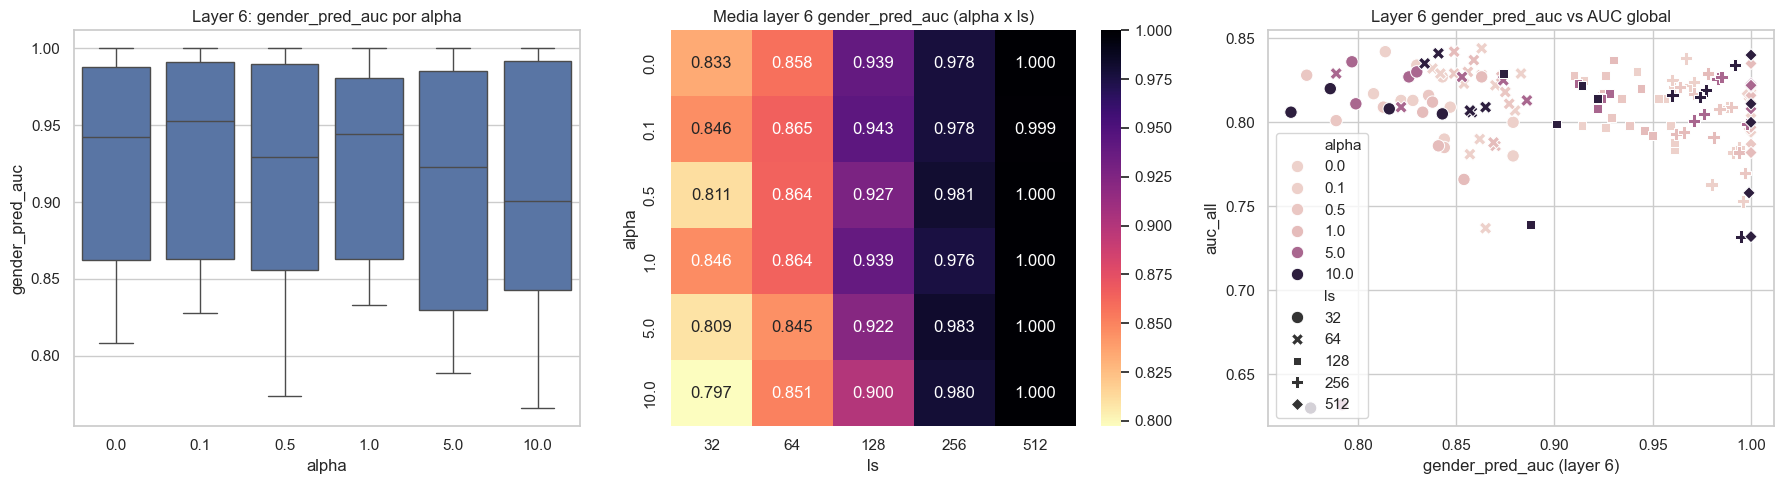

In [7]:
# Visualizaciones de layer 6: señal de género vs rendimiento
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=layer6, x="alpha", y="gender_pred_auc", ax=axes[0])
axes[0].set_title("Layer 6: gender_pred_auc por alpha")
axes[0].set_xlabel("alpha")
axes[0].set_ylabel("gender_pred_auc")

pivot_l6 = layer6.groupby(["alpha", "ls"])["gender_pred_auc"].mean().unstack()
sns.heatmap(pivot_l6, annot=True, fmt=".3f", cmap="magma_r", ax=axes[1])
axes[1].set_title("Media layer 6 gender_pred_auc (alpha x ls)")

sns.scatterplot(data=layer6, x="gender_pred_auc", y="auc_all", hue="alpha", style="ls", s=80, ax=axes[2])
axes[2].set_title("Layer 6 gender_pred_auc vs AUC global")
axes[2].set_xlabel("gender_pred_auc (layer 6)")
axes[2].set_ylabel("auc_all")

plt.tight_layout()
plt.show()